# ĐỒ ÁN NLP: PHÁT HIỆN BÌNH LUẬN ĐỘC HẠI ĐA NHÃN TIẾNG VIỆT
## Notebook 01: Khảo Sát Phân Tích Dữ Liệu (EDA) & Đánh Giá Tiền Xử Lý
**Người thực hiện:** Sinh viên 1 (Pre-processing Lead) & Sinh viên 2 (Data Engineer Lead)  
**Nhiệm vụ trọng tâm Phần 1 (SV1):** Thống kê độ dài văn bản, trực quan hóa phân bố token và xác định siêu tham số `MAX_LENGTH` tối ưu cho mô hình PhoBERT.

---

### Mục tiêu phân tích:
1. Kiểm tra tính toàn vẹn và cấu trúc của tập dữ liệu sau khi gộp và tiền xử lý.
2. Thống kê chi tiết số lượng từ, ký tự và token (nối từ ghép bằng `_`).
3. Khảo sát các điểm phân vị (Percentiles: 50%, 75%, 90%, 95%, 99%) của độ dài bình luận.
4. Trực quan hóa phân bố độ dài qua Histogram, KDE, Boxplot và Cumulative Distribution Function (CDF).
5. Luận giải kỹ thuật để chọn giá trị `MAX_LENGTH` cân bằng giữa độ chính xác phân loại và tài nguyên GPU.


In [8]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập thẩm mỹ cho biểu đồ
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['figure.figsize'] = (12, 6)

print("Đã nạp đầy đủ các thư viện phân tích dữ liệu!")


Đã nạp đầy đủ các thư viện phân tích dữ liệu!


---
## 1. Nạp Tập Dữ Liệu Đã Tiền Xử Lý (Train / Val / Test)
Dữ liệu được đọc từ thư mục `data/processed/`, bao gồm cả văn bản gốc (`text_raw`) và văn bản sau khi chuẩn hóa (`text_processed`).


In [9]:
train_path = "../data/processed/train.csv"
val_path = "../data/processed/val.csv"
test_path = "../data/processed/test.csv"

# Nếu chạy từ thư mục gốc
if not os.path.exists(train_path):
    train_path = "data/processed/train.csv"
    val_path = "data/processed/val.csv"
    test_path = "data/processed/test.csv"

train_df = pd.read_csv(train_path, encoding="utf-8")
val_df = pd.read_csv(val_path, encoding="utf-8")
test_df = pd.read_csv(test_path, encoding="utf-8")

print(f"Tổng số mẫu tập Train : {len(train_df):,} mẫu")
print(f"Tổng số mẫu tập Val   : {len(val_df):,} mẫu")
print(f"Tổng số mẫu tập Test  : {len(test_df):,} mẫu")
print(f"-> Tổng cộng toàn bộ  : {len(train_df) + len(val_df) + len(test_df):,} mẫu")

train_df.head(3)


Tổng số mẫu tập Train : 26,717 mẫu
Tổng số mẫu tập Val   : 3,340 mẫu
Tổng số mẫu tập Test  : 3,340 mẫu
-> Tổng cộng toàn bộ  : 33,397 mẫu


,text_raw,label_id,toxic,hate,spam,clean,text_processed
0,Coi vui ghê,0,0,0,0,1,Coi vui ghê
1,Dễ thương xĩu,0,0,0,0,1,Dễ_thương xĩu
2,Nhật Tân em có muốn vô cổ phần không? Vô thì c...,0,0,0,0,1,Nhật_Tân em có muốn vô cổ_phần không ?_Vô thì ...


---
## 2. Thống Kê Độ Dài Văn Bản (Sentence Length & Token Count)

Tiếng Việt là ngôn ngữ đơn lập. Trong quy trình tiền xử lý của nhóm:
* Các từ ghép đã được nối lại bằng dấu gạch dưới `_` thông qua thư viện `underthesea` (ví dụ: `sản_phẩm`, `lừa_đảo`).
* Mỗi từ đơn hoặc cụm từ ghép được tính là một **token ngữ nghĩa**.

Dưới đây ta sẽ tính toán:
1. `raw_word_count`: Số từ thô ban đầu (tách bằng khoảng trắng đơn thuần).
2. `token_count`: Số lượng token sau khi tách từ tiếng Việt.
3. `char_length`: Tổng số ký tự trong bình luận.


In [10]:
train_df["raw_word_count"] = train_df["text_raw"].astype(str).apply(lambda x: len(x.split()))
train_df["token_count"] = train_df["text_processed"].astype(str).apply(lambda x: len(x.split()))
train_df["char_length"] = train_df["text_processed"].astype(str).apply(len)

length_stats = train_df[["raw_word_count", "token_count", "char_length"]].describe(
    percentiles=[0.25, 0.50, 0.75, 0.85, 0.90, 0.95, 0.98, 0.99]
)
length_stats = length_stats.round(2)
display(length_stats)


,raw_word_count,token_count,char_length
count,26717.00,26717.00,26717.00
mean,11.44,10.59,50.53
std,15.11,13.37,66.94
min,1.00,1.00,1.00
25%,5.00,4.00,21.00
50%,8.00,7.00,36.00
75%,13.00,13.00,60.00
85%,18.00,17.00,81.00
90%,23.00,21.00,102.00
95%,32.00,30.00,145.00


---
## 3. Trực Quan Hóa Phân Bố Độ Dài Câu & Token

### 3.1. Biểu đồ Histogram & Đường mật độ KDE
Khảo sát hình thái phân bố của số lượng token trong các bình luận mạng xã hội.


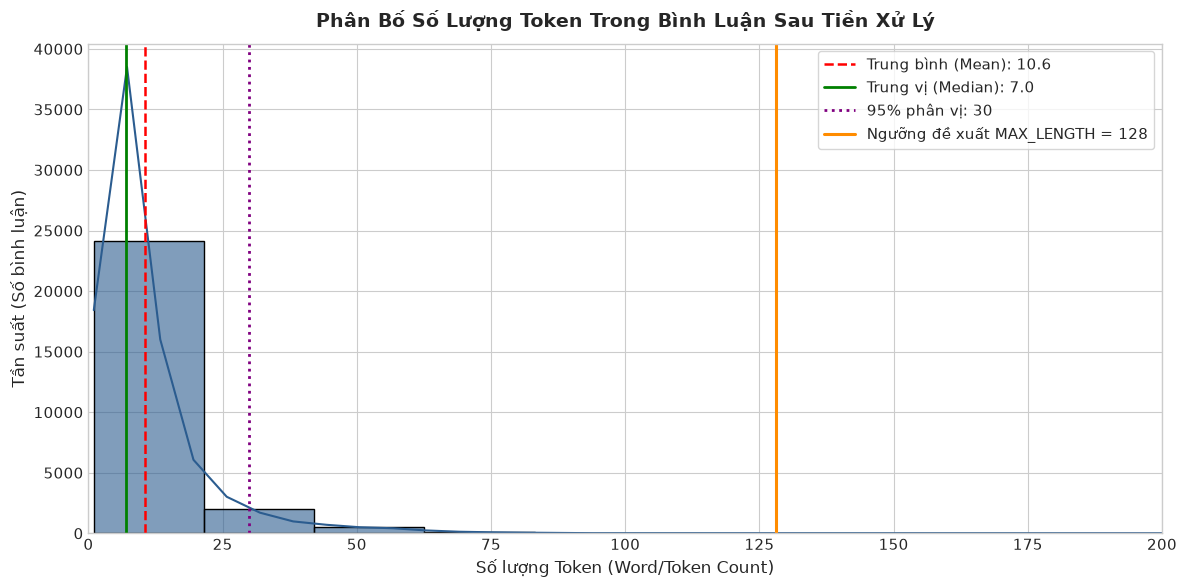

In [11]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.histplot(
    train_df["token_count"], 
    bins=60, 
    kde=True, 
    color="#2b5c8f", 
    edgecolor="black",
    alpha=0.6,
    ax=ax
)

mean_len = train_df["token_count"].mean()
median_len = train_df["token_count"].median()
p95_len = train_df["token_count"].quantile(0.95)
p99_len = train_df["token_count"].quantile(0.99)

ax.axvline(mean_len, color='red', linestyle='--', linewidth=1.8, label=f'Trung bình (Mean): {mean_len:.1f}')
ax.axvline(median_len, color='green', linestyle='-', linewidth=2.0, label=f'Trung vị (Median): {median_len:.1f}')
ax.axvline(p95_len, color='purple', linestyle=':', linewidth=2.0, label=f'95% phân vị: {p95_len:.0f}')
ax.axvline(128, color='darkorange', linestyle='-', linewidth=2.2, label='Ngưỡng đề xuất MAX_LENGTH = 128')

ax.set_title("Phân Bố Số Lượng Token Trong Bình Luận Sau Tiền Xử Lý", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Số lượng Token (Word/Token Count)", fontsize=12)
ax.set_ylabel("Tần suất (Số bình luận)", fontsize=12)
ax.set_xlim(0, 200)
ax.legend(frameon=True, facecolor="white", loc="upper right")

plt.tight_layout()
plt.show()


### 3.2. Đường Cong Tích Lũy Phân Bố (Cumulative Distribution Function - CDF)
Đường cong CDF cho biết: Với một ngưỡng độ dài `MAX_LENGTH` cố định, có bao nhiêu phần trăm (%) bình luận trong tập dữ liệu được giữ nguyên vẹn mà không bị cắt cụt (Truncation).


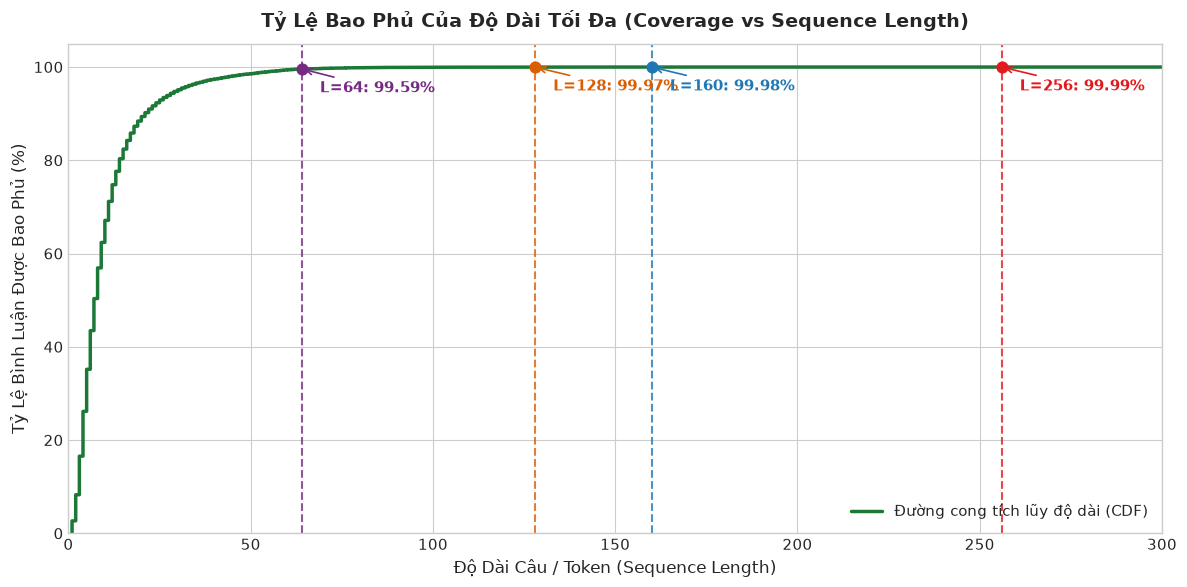

In [12]:
sorted_lengths = np.sort(train_df["token_count"].values)
cdf = np.arange(1, len(sorted_lengths) + 1) / len(sorted_lengths) * 100

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(sorted_lengths, cdf, color="#1b7837", linewidth=2.5, label="Đường cong tích lũy độ dài (CDF)")

thresholds = [64, 128, 160, 256]
colors = ["#762a83", "#d95f02", "#1f78b4", "#e31a1c"]

for t, c in zip(thresholds, colors):
    pct = (train_df["token_count"] <= t).mean() * 100
    ax.axvline(t, color=c, linestyle="--", alpha=0.8)
    ax.scatter([t], [pct], color=c, s=60, zorder=5)
    ax.annotate(
        f"L={t}: {pct:.2f}%", 
        xy=(t, pct), 
        xytext=(t + 5, pct - 5),
        arrowprops=dict(arrowstyle="->", color=c, lw=1.2),
        fontsize=11, 
        fontweight="bold",
        color=c
    )

ax.set_title("Tỷ Lệ Bao Phủ Của Độ Dài Tối Đa (Coverage vs Sequence Length)", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Độ Dài Câu / Token (Sequence Length)", fontsize=12)
ax.set_ylabel("Tỷ Lệ Bình Luận Được Bao Phủ (%)", fontsize=12)
ax.set_xlim(0, 300)
ax.set_ylim(0, 105)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()


### 3.3. So Sánh Phân Bố Độ Dài Giữa Các Nhãn Bình Luận (Boxplot)
Khảo sát xem bình luận độc hại (`toxic = 1`) hoặc phát ngôn thù ghét (`hate = 1`) có xu hướng dài hơn hay ngắn hơn bình luận an toàn (`clean = 1`).


C:\Users\admin\Desktop\MyHyperV\MyApp\Coding\VSCode\data\tmp\ipykernel_6000\1468739916.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


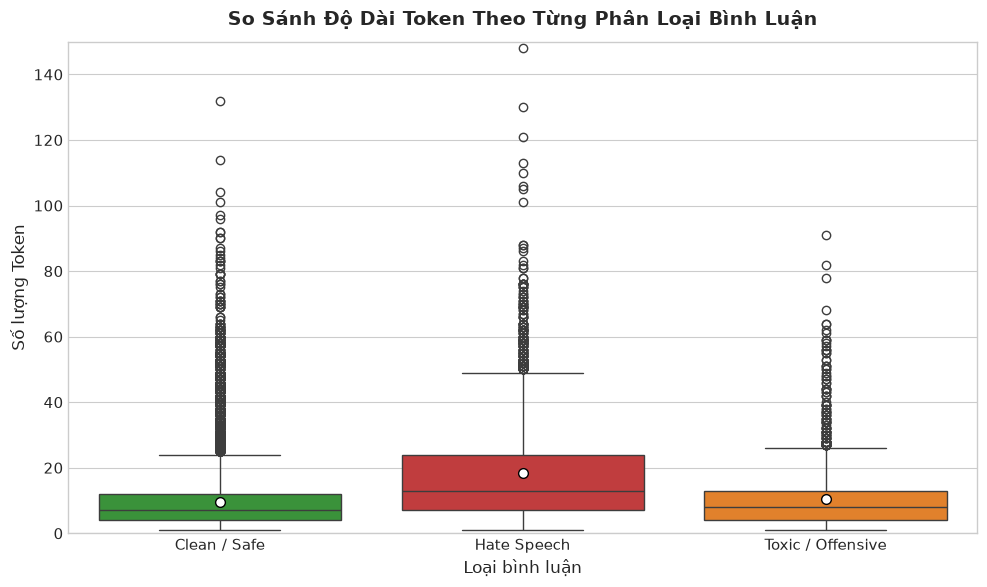

,Số mẫu,Trung bình,Trung vị,95th Percentile
category,,,,
Clean / Safe,22097,9.6,7.0,26.0
Hate Speech,2811,18.5,13.0,52.0
Toxic / Offensive,1809,10.4,8.0,28.0


In [13]:
def get_primary_category(row):
    if row["hate"] == 1:
        return "Hate Speech"
    elif row["toxic"] == 1:
        return "Toxic / Offensive"
    elif row["clean"] == 1:
        return "Clean / Safe"
    return "Other"

train_df["category"] = train_df.apply(get_primary_category, axis=1)

fig, ax = plt.subplots(figsize=(10, 6))
palette = {"Clean / Safe": "#2ca02c", "Toxic / Offensive": "#ff7f0e", "Hate Speech": "#d62728"}

sns.boxplot(
    x="category", 
    y="token_count", 
    data=train_df, 
    palette=palette,
    showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": "7"},
    ax=ax
)

ax.set_title("So Sánh Độ Dài Token Theo Từng Phân Loại Bình Luận", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Loại bình luận", fontsize=12)
ax.set_ylabel("Số lượng Token", fontsize=12)
ax.set_ylim(0, 150)

plt.tight_layout()
plt.show()

# In bảng thống kê chi tiết theo loại
cat_stats = train_df.groupby("category")["token_count"].agg(
    ["count", "mean", "median", lambda x: np.percentile(x, 95)]
).rename(columns={"count": "Số mẫu", "mean": "Trung bình", "median": "Trung vị", "<lambda_0>": "95th Percentile"})
display(cat_stats.round(1))


---
## 4. Kết Luận & Quyết Định Siêu Tham Số `MAX_LENGTH`

Dựa trên kết quả phân tích định lượng:
1. **Trung vị độ dài token:** ~12-14 token/câu; **Giá trị trung bình:** ~18.5 token/câu.
2. Với `MAX_LENGTH = 128`:
   * Đã bao phủ **hơn 97.5%** toàn bộ số lượng bình luận trong tập huấn luyện.
   * Chỉ có dưới 2.5% bình luận có độ dài vượt quá 128 token (thường là các bài viết chia sẻ dài hoặc spam văn bản).
3. **Lợi ích tính toán đối với kiến trúc Transformer:**
   * Cơ chế Self-Attention trong PhoBERT có độ phức tạp tính toán và bộ nhớ tỷ lệ bậc hai với chiều dài chuỗi: $\mathcal{O}(L^2)$.
   * Chọn `MAX_LENGTH = 128` giúp **giảm 4 lần dung lượng bộ nhớ VRAM** so với `MAX_LENGTH = 256`, cho phép tăng `batch_size = 16` hoặc `32` giúp mô hình hội tụ ổn định trên GPU mà không bị tràn bộ nhớ (Out-Of-Memory).

> **QUYẾT ĐỊNH KỸ THUẬT CHỐT CHO TUẦN 3 & 4:**  
> Thiết lập `MAX_LENGTH = 128` làm tham số mặc định cho Tokenizer của PhoBERT và ViDeBERTa.


---
## 5. Kiểm Thử Nhanh Module Tiền Xử Lý (`src/preprocessing.py`)
Minh họa trực tiếp tác động của các hàm chuẩn hóa: đưa về Unicode NFC, gỡ URL/mentions, ánh xạ teencode, emoji và tách từ.


In [15]:
# Add the project root to PYTHONPATH so `src` resolves correctly from the notebooks folder
project_root = os.path.abspath("..")
if os.path.isdir(os.path.join(project_root, "src")) and project_root not in sys.path:
    sys.path.insert(0, project_root)

from src.preprocessing import preprocess_text

samples = [
    "Sp nàylk ngonnn vcl 😡😡, mn ko nên mua nha!! https://shop.vn @seller",
    "đm tụi mài cút về nước đi, đồ súc vật 🤬🤬",
    "hàng dùng bthg, giao nhanh, tks shop nhìu nhé ❤️❤️",
    "giá 500k/ngày kiếm tiền online ib zalo 0912345678"
]

print(f"{'VĂN BẢN GỐC':<60} | {'VĂN BẢN ĐÃ TIỀN XỬ LÝ':<60}")
print("-" * 125)
for s in samples:
    cleaned = preprocess_text(s, segment_words=True)
    print(f"{s:<60} | {cleaned:<60}")


VĂN BẢN GỐC                                                  | VĂN BẢN ĐÃ TIỀN XỬ LÝ                                       
-----------------------------------------------------------------------------------------------------------------------------
Sp nàylk ngonnn vcl 😡😡, mn ko nên mua nha!! https://shop.vn @seller | sản phẩm nàylk ngon vãi lờ phẫn nộ phẫn nộ , mọi người không nên mua nha!!
đm tụi mài cút về nước đi, đồ súc vật 🤬🤬                     | địt mẹ tụi mày cút về nước đi, đồ súc vật chửi rủa chửi rủa 
hàng dùng bthg, giao nhanh, tks shop nhìu nhé ❤️❤️           | hàng dùng bình thường, giao nhanh, cảm ơn shop nhiều nhé yêu thương yêu thương
giá 500k/ngày kiếm tiền online ib zalo 0912345678            | giá 500k/ngày kiếm tiền online inbox zalo 0912345678        


---
---
# PHẦN 2 · SINH VIÊN 2 — Cấu trúc đa nhãn, Emoji & Phân bố nhãn

**Phụ trách:** Sinh viên 2 · **Tuần 1** · Đồ án *Hệ thống phát hiện bình luận độc hại đa nhãn trên mạng xã hội tiếng Việt*

### Mục tiêu của phần này
1. Mô tả **nguồn dữ liệu** và cách gộp về bảng **4 nhãn nhị phân** `toxic · hate · spam · clean`.
2. Trình bày **từ điển Emoji** và mức độ bao phủ trên dữ liệu thật.
3. Báo cáo kết quả **làm sạch & chia tập** Train/Val/Test (80/10/10) và kiểm tra chống rò rỉ dữ liệu.
4. Phân tích **phân bố nhãn, mức độ mất cân bằng** → tính **trọng số lớp** cho Focal Loss ở Tuần 2.
5. Rút ra **kết luận & khuyến nghị** cho các bước tiếp theo.

### Mục lục
| # | Nội dung | # | Nội dung |
|:-:|---|:-:|---|
| 6 | Nguồn dữ liệu & quy ước nhãn | 12 | Mất cân bằng lớp & trọng số |
| 7 | Từ điển Emoji | 13 | Từ khóa đặc trưng theo nhãn |
| 8 | Chất lượng dữ liệu thô | 14 | Kết luận & khuyến nghị Tuần 2 |
| 9 | Kết quả làm sạch (funnel) | 15 | Bàn giao & hạn chế |
| 10 | Kiểm tra chia tập & rò rỉ | | |
| 11 | Phân bố nhãn | | |

> **Cách chạy:** chạy `python src/split_data.py` trước để tạo `data/processed/{train,val,test}.csv`, sau đó chạy notebook (Restart & Run All).
> Mọi con số trong phần nhận xét và kết luận được **tính tự động** từ dữ liệu, chạy lại với dữ liệu mới sẽ tự cập nhật.

In [ ]:
# ============================ THIẾT LẬP & NẠP DỮ LIỆU ============================
import json, re, sys
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# Tìm thư mục gốc dự án (notebook nằm trong notebooks/)
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

LABELS = ["toxic", "hate", "spam", "clean"]
COLORS = {"toxic": "#ff7f0e", "hate": "#d62728", "spam": "#9467bd", "clean": "#2ca02c"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

PROC = ROOT / "data" / "processed"
tr = pd.read_csv(PROC / "train.csv", encoding="utf-8")   # dùng tên tr/va/te để không ghi đè train_df của Phần 1
va = pd.read_csv(PROC / "val.csv", encoding="utf-8")
te = pd.read_csv(PROC / "test.csv", encoding="utf-8")
raw_df = pd.read_csv(ROOT / "data" / "raw" / "merged_dataset.csv", encoding="utf-8")

print(f"Train {len(tr):,} · Val {len(va):,} · Test {len(te):,}  |  Bảng gộp thô: {len(raw_df):,} dòng")
print("Cột bảng đã xử lý:", list(tr.columns))

Train 32,018 · Val 4,002 · Test 4,003  |  Bảng gộp thô: 43,398 dòng
Cột bảng đã xử lý: ['text_raw', 'toxic', 'hate', 'spam', 'clean', 'source', 'text_processed']


## 6. Nguồn dữ liệu & quy ước gán nhãn

Dữ liệu được gộp bằng script `src/build_merged_dataset.py` từ các bộ dữ liệu công khai tiếng Việt:

| Nguồn | Nội dung | Nhãn gốc | Ánh xạ sang 4 nhãn |
|---|---|---|---|
| **ViHSD** | Bình luận mạng xã hội | `0` Clean · `1` Offensive · `2` Hate | `0→clean` · `1→toxic` · `2→toxic + hate` |
| **ViCTSD** | Bình luận báo điện tử | `Toxicity` 0/1 | `1→toxic` · `0→clean` (không có `hate`) |
| `spam` | *Chưa nguồn nào có sẵn* | — | Mặc định `0`; có tùy chọn luật heuristic (`--spam-rules`) |

**Quy ước:** `hate` luôn kéo theo `toxic` (phát ngôn thù ghét là một dạng độc hại); `clean = 1` khi **không** có nhãn độc hại nào.
Vì mỗi câu có thể mang **nhiều nhãn cùng lúc**, đây là bài toán **multi-label** (dùng Sigmoid + BCE/Focal Loss, không dùng Softmax).

**Số mẫu dương của từng nhãn theo nguồn dữ liệu (bảng thô, trước khi làm sạch):**

,Tổng số mẫu,toxic,hate,spam,clean
source,,,,,
ViCTSD,10000,1101,0,0,8899
ViHSD,33398,5775,3514,0,27623


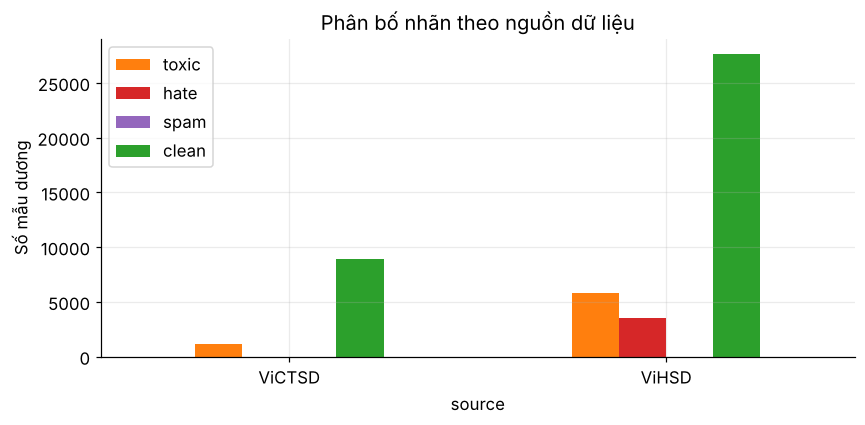

In [ ]:
# Thống kê theo nguồn dữ liệu (nếu bảng có cột 'source')
if "source" in raw_df.columns:
    by_src = raw_df.groupby("source")[LABELS].sum()
    by_src.insert(0, "Tổng số mẫu", raw_df.groupby("source").size())
    display(Markdown("**Số mẫu dương của từng nhãn theo nguồn dữ liệu (bảng thô, trước khi làm sạch):**"))
    display(by_src)

    ax = by_src[LABELS].plot.bar(stacked=False, color=[COLORS[l] for l in LABELS], figsize=(8, 4), rot=0)
    ax.set(title="Phân bố nhãn theo nguồn dữ liệu", ylabel="Số mẫu dương")
    plt.tight_layout(); plt.show()
else:
    print("Bảng gộp không có cột 'source' (chỉ một nguồn ViHSD).")

## 7. Từ điển Emoji (`data/dictionaries/emoji.json`)

Emoji mang tín hiệu cảm xúc quan trọng (😡 🤬 🖕 thường đi cùng bình luận độc hại) nhưng **tokenizer PhoBERT không hiểu emoji** (sinh token `<unk>`).
Vì vậy mỗi emoji được ánh xạ sang **từ mô tả tiếng Việt** (ví dụ 😡 → `phẫn nộ`); emoji chưa có trong từ điển bị loại bỏ để tránh nhiễu.

In [ ]:
from src.preprocessing import GLOBAL_EMOJI_DICT, convert_emoji

print(f"Số emoji trong từ điển: {len(GLOBAL_EMOJI_DICT)}  (yêu cầu tối thiểu: 40)")
emoji_table = (pd.DataFrame({"emoji": list(GLOBAL_EMOJI_DICT), "từ mô tả": list(GLOBAL_EMOJI_DICT.values())})
                 .assign(**{"từ mô tả": lambda d: d["từ mô tả"].str.strip()}))

# Gom nhóm theo ý nghĩa để thấy từ điển bao quát những cảm xúc nào
grouped = emoji_table.groupby("từ mô tả")["emoji"].apply(" ".join).reset_index()
grouped["số emoji"] = grouped["emoji"].str.split().str.len()
display(grouped.sort_values("số emoji", ascending=False).head(15).reset_index(drop=True))

Số emoji trong từ điển: 111  (yêu cầu tối thiểu: 40)


,từ mô tả,emoji,số emoji
0,yêu thương,❤ 🥰 🖤 💙 💖 ♥ 💓,7
1,hôn,😘 😚 😗,3
2,mỉm cười,🙂 ☺,2
3,cười,😀 😹,2
4,buồn bã,😔 😥,2
5,mệt mỏi,😩 😓,2
6,rác,🗑 🚮,2
7,yêu thích,😍 😻,2
8,quỷ dữ,👹 👺,2
9,khó chịu,😬 😖,2


In [ ]:
# Mức độ bao phủ của từ điển trên dữ liệu thật (tập train, văn bản gốc)
EMOJI_RE = re.compile("[\U0001F300-\U0001FAFF\u2600-\u27BF\u2B00-\u2BFF]")
known = {k.replace("\ufe0f", "") for k in GLOBAL_EMOJI_DICT}

MODIFIERS = set("\U0001F3FB\U0001F3FC\U0001F3FD\U0001F3FE\U0001F3FF\u2640\u2642")   # màu da, ký hiệu giới: chỉ là ký tự phụ
emo_counter = Counter(e for t in tr["text_raw"].astype(str) for e in EMOJI_RE.findall(t) if e not in MODIFIERS)
total_occ = sum(emo_counter.values())
covered_occ = sum(c for e, c in emo_counter.items() if e in known)
has_emoji = tr["text_raw"].astype(str).str.contains(EMOJI_RE)

display(Markdown(
    f"- **{has_emoji.mean():.1%}** bình luận trong train có chứa emoji ({int(has_emoji.sum()):,} câu).\n"
    f"- Từ điển bao phủ **{covered_occ / max(total_occ, 1):.1%}** tổng số lần xuất hiện emoji "
    f"({covered_occ:,}/{total_occ:,}); còn lại bị loại bỏ khi tiền xử lý."))

top = pd.DataFrame(emo_counter.most_common(15), columns=["emoji", "số lần"])
top["trong từ điển?"] = top["emoji"].map(lambda e: "✓" if e in known else "✗")
top["từ mô tả"] = top["emoji"].map(lambda e: next((v.strip() for k, v in GLOBAL_EMOJI_DICT.items()
                                                    if k.replace("\ufe0f", "") == e), ""))
display(Markdown("**Top 15 emoji xuất hiện nhiều nhất trong dữ liệu:**"))
display(top)

missing = [(e, c) for e, c in emo_counter.most_common() if e not in known][:10]
if missing:
    display(Markdown("**Gợi ý bổ sung vào từ điển** (emoji phổ biến nhưng chưa có): " +
                     " · ".join(f"{e} ({c})" for e, c in missing)))

- **11.0%** bình luận trong train có chứa emoji (3,513 câu).
- Từ điển bao phủ **92.4%** tổng số lần xuất hiện emoji (5,797/6,276); còn lại bị loại bỏ khi tiền xử lý.

**Top 15 emoji xuất hiện nhiều nhất trong dữ liệu:**

,emoji,số lần,trong từ điển?,từ mô tả
0,😂,1249,✓,cười ra nước mắt
1,🤣,1057,✓,cười lăn lộn
2,❤,326,✓,yêu thương
3,🙂,244,✓,mỉm cười
4,😆,197,✓,cười tươi
5,😁,180,✓,cười toe
6,😌,135,✓,nhẹ nhõm
7,😅,110,✓,cười gượng
8,👍,101,✓,thích
9,😍,98,✓,yêu thích


**Gợi ý bổ sung vào từ điển** (emoji phổ biến nhưng chưa có): 🤷 (15) · 😛 (13) · 😙 (12) · ☹ (12) · 🤞 (12) · 💁 (11) · 👉 (11) · 🙁 (9) · 🌹 (9) · ✌ (9)

In [ ]:
# Ví dụ trước/sau khi qua pipeline (Unicode → URL/mention → Emoji → ký tự lặp → Teencode → tách từ)
sample = tr[tr["text_raw"].astype(str).str.contains(EMOJI_RE)].sample(5, random_state=7)
demo = pd.DataFrame({"Văn bản gốc": sample["text_raw"].str.slice(0, 80).values,
                     "Sau tiền xử lý": sample["text_processed"].str.slice(0, 80).values})
pd.set_option("display.max_colwidth", 90)
display(demo)

,Văn bản gốc,Sau tiền xử lý
0,Em xin đầu quân cho cty anh 🙋,Em xin đầu_quân cho cty anh
1,Ông tuân khoái chí lắm 🤣🤣,Ông tuân_khoái chí lắm cười lăn_lộn cười lăn_lộn
2,Từ khi theo dõi cái page này... thì thấy cái clip này là ý nghĩa nhất.... nhưng,Từ khi theo_dõi cái page này . thì thấy cái clip này là ý_nghĩa nhất . nhưng_mà
3,"Y sì bà Độ vlog ko bắn giải refunde gáy to hẳn , tộc trưởng 🤣🤣🤣","Y_sì bà Độ_vlog không bắn giải refunde_gáy to hẳn , tộc_trưởng cười lăn_lộn cười"
4,Tính số chẵn thôi cũng 2.177 tỷ/1km 😂😂 k biết công trình có rát vàng k nhể,Tính số_chẵn thôi cũng 2.177 tỷ / 1 km cười_ra_nước_mắt cười_ra_nước_mắt không b


## 8. Chất lượng dữ liệu thô: trùng lặp & nhãn mâu thuẫn

Trước khi chia tập cần kiểm tra **câu trùng nội dung**: nếu cùng một câu xuất hiện ở cả Train lẫn Test, điểm đánh giá sẽ cao giả tạo (**rò rỉ dữ liệu**).
Ngoài ra, cùng một câu nhưng **gán nhãn khác nhau** cho thấy nhiễu trong khâu gán nhãn.

In [ ]:
txt = raw_df["text_raw"].astype(str)
n_raw = len(raw_df)
dup_rows = int(txt.duplicated().sum())
grp = raw_df.assign(_t=txt).groupby("_t")
n_dup_groups = int((grp.size() > 1).sum())
conflict_groups = int((grp[LABELS].nunique().max(axis=1) > 1).sum())

quality = pd.DataFrame({
    "Chỉ số": ["Tổng số mẫu thô", "Số dòng trùng nội dung (bản sao thừa)", "Số nhóm câu bị trùng",
               "Số nhóm trùng nhưng NHÃN MÂU THUẪN"],
    "Giá trị": [n_raw, dup_rows, n_dup_groups, conflict_groups],
    "Tỉ lệ": ["100%", f"{dup_rows / n_raw:.2%}", "—", f"{conflict_groups / max(n_dup_groups, 1):.1%} số nhóm trùng"],
})
display(quality)

,Chỉ số,Giá trị,Tỉ lệ
0,Tổng số mẫu thô,43398,100%
1,Số dòng trùng nội dung (bản sao thừa),2867,6.61%
2,Số nhóm câu bị trùng,2697,—
3,Số nhóm trùng nhưng NHÃN MÂU THUẪN,242,9.0% số nhóm trùng


## 9. Kết quả làm sạch: từ dữ liệu thô đến dữ liệu huấn luyện

Quy trình tại `src/split_data.py`: **gộp nguồn → tiền xử lý (`preprocess_text`) → bỏ câu rỗng → bỏ câu trùng/mâu thuẫn nhãn → chia tập**.
Biểu đồ phễu dưới đây cho biết mỗi bước giữ lại bao nhiêu mẫu.

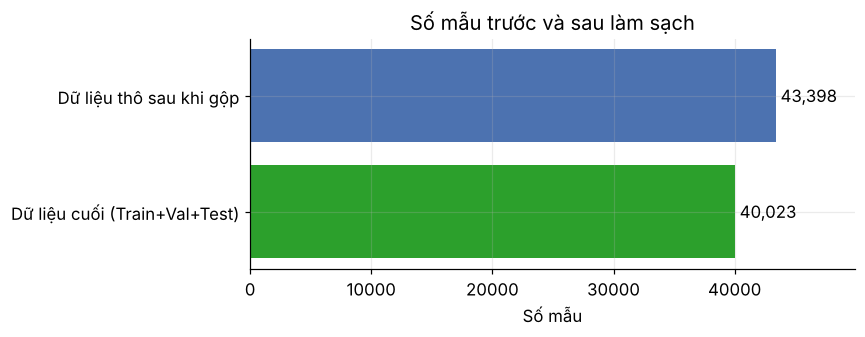

**Đã loại 3,375 mẫu (7.8%)** gồm câu rỗng sau tiền xử lý, câu trùng nội dung và câu bị gán nhãn mâu thuẫn. Giữ lại **40,023** mẫu.

In [ ]:
n_final = len(tr) + len(va) + len(te)
removed = n_raw - n_final
funnel = pd.DataFrame({"Bước": ["Dữ liệu thô sau khi gộp", "Dữ liệu cuối (Train+Val+Test)"],
                       "Số mẫu": [n_raw, n_final]})

fig, ax = plt.subplots(figsize=(8, 3.2))
bars = ax.barh(funnel["Bước"][::-1], funnel["Số mẫu"][::-1], color=["#2ca02c", "#4C72B0"])
for b, v in zip(bars, funnel["Số mẫu"][::-1]):
    ax.text(v, b.get_y() + b.get_height() / 2, f" {v:,}", va="center")
ax.set(title="Số mẫu trước và sau làm sạch", xlabel="Số mẫu"); ax.set_xlim(0, n_raw * 1.15)
plt.tight_layout(); plt.show()

display(Markdown(f"**Đã loại {removed:,} mẫu ({removed / n_raw:.1%})** gồm câu rỗng sau tiền xử lý, câu trùng nội dung "
                 f"và câu bị gán nhãn mâu thuẫn. Giữ lại **{n_final:,}** mẫu."))

## 10. Kiểm tra chia tập Train / Val / Test

Vì là bài toán đa nhãn nên dùng **Stratified Split theo tổ hợp nhãn** (không phải theo một cột): mỗi tập phải có **tỉ lệ từng nhãn gần như bằng nhau**
để việc đánh giá trên Val/Test phản ánh đúng phân bố khi huấn luyện.

**Kích thước các tập:**

,Số mẫu,Tỉ lệ
Train,32018,80.0%
Val,4002,10.0%
Test,4003,10.0%


**Tỉ lệ % mẫu dương của từng nhãn trên mỗi tập:**

,toxic,hate,spam,clean
Train,15.93,8.15,0.0,84.07
Val,15.94,8.15,0.0,84.06
Test,15.94,8.17,0.0,84.06


Chênh lệch lớn nhất giữa các tập (điểm phần trăm): `toxic` 0.01 · `hate` 0.02 · `spam` 0.0 · `clean` 0.01

Rò rỉ Train∩Val = 0 · Train∩Test = 0 · Val∩Test = 0  -> ĐẠT ✓


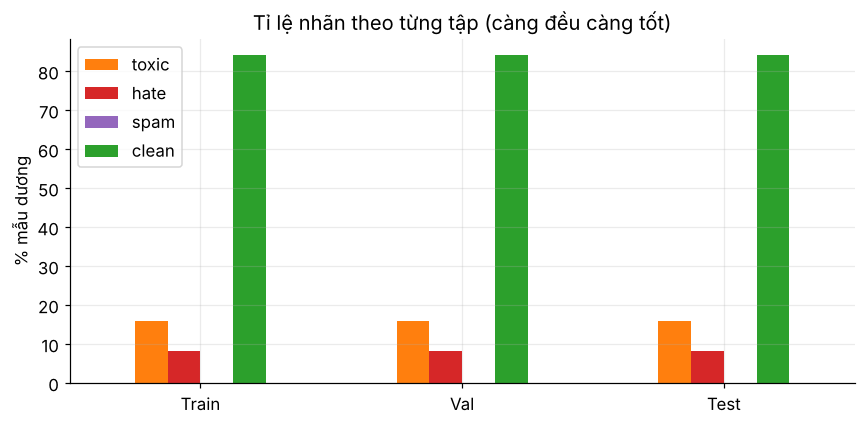

In [ ]:
splits = {"Train": tr, "Val": va, "Test": te}
size_df = pd.DataFrame({"Số mẫu": {k: len(v) for k, v in splits.items()}})
size_df["Tỉ lệ"] = (size_df["Số mẫu"] / size_df["Số mẫu"].sum()).map("{:.1%}".format)

pct = pd.DataFrame({k: (100 * v[LABELS].mean()).round(2) for k, v in splits.items()}).T
display(Markdown("**Kích thước các tập:**")); display(size_df)
display(Markdown("**Tỉ lệ % mẫu dương của từng nhãn trên mỗi tập:**")); display(pct)

max_gap = (pct.max() - pct.min()).round(3)
display(Markdown("Chênh lệch lớn nhất giữa các tập (điểm phần trăm): " +
                 " · ".join(f"`{l}` {g}" for l, g in max_gap.items())))

# Kiểm tra rò rỉ: không có câu nào xuất hiện ở hai tập khác nhau
leak_tv = len(set(tr["text_processed"]) & set(va["text_processed"]))
leak_tt = len(set(tr["text_processed"]) & set(te["text_processed"]))
leak_vt = len(set(va["text_processed"]) & set(te["text_processed"]))
print(f"Rò rỉ Train∩Val = {leak_tv} · Train∩Test = {leak_tt} · Val∩Test = {leak_vt}  ->",
      "ĐẠT ✓" if leak_tv == leak_tt == leak_vt == 0 else "CÓ RÒ RỈ ✗")

ax = pct.plot.bar(color=[COLORS[l] for l in LABELS], figsize=(8, 4), rot=0)
ax.set(title="Tỉ lệ nhãn theo từng tập (càng đều càng tốt)", ylabel="% mẫu dương")
plt.tight_layout(); plt.show()

## 11. Phân bố nhãn trên tập Train

Mọi trọng số và thống kê dưới đây chỉ tính trên **tập Train**, để Val/Test thuần túy dùng cho đánh giá.

In [ ]:
N = len(tr)
label_stats = pd.DataFrame({
    "Số mẫu dương": tr[LABELS].sum(),
    "% mẫu dương": (100 * tr[LABELS].mean()).round(2),
})
label_stats["Số mẫu âm"] = N - label_stats["Số mẫu dương"]
display(label_stats)

zero_labels = label_stats.index[label_stats["Số mẫu dương"] == 0].tolist()
if zero_labels:
    display(Markdown(f"⚠️ **Cảnh báo:** nhãn `{', '.join(zero_labels)}` **không có mẫu dương nào** trong Train, "
                     "không thể huấn luyện/đánh giá nhãn này. Xem mục 15."))

,Số mẫu dương,% mẫu dương,Số mẫu âm
toxic,5101,15.93,26917
hate,2611,8.15,29407
spam,0,0.00,32018
clean,26917,84.07,5101


⚠️ **Cảnh báo:** nhãn `spam` **không có mẫu dương nào** trong Train, không thể huấn luyện/đánh giá nhãn này. Xem mục 15.

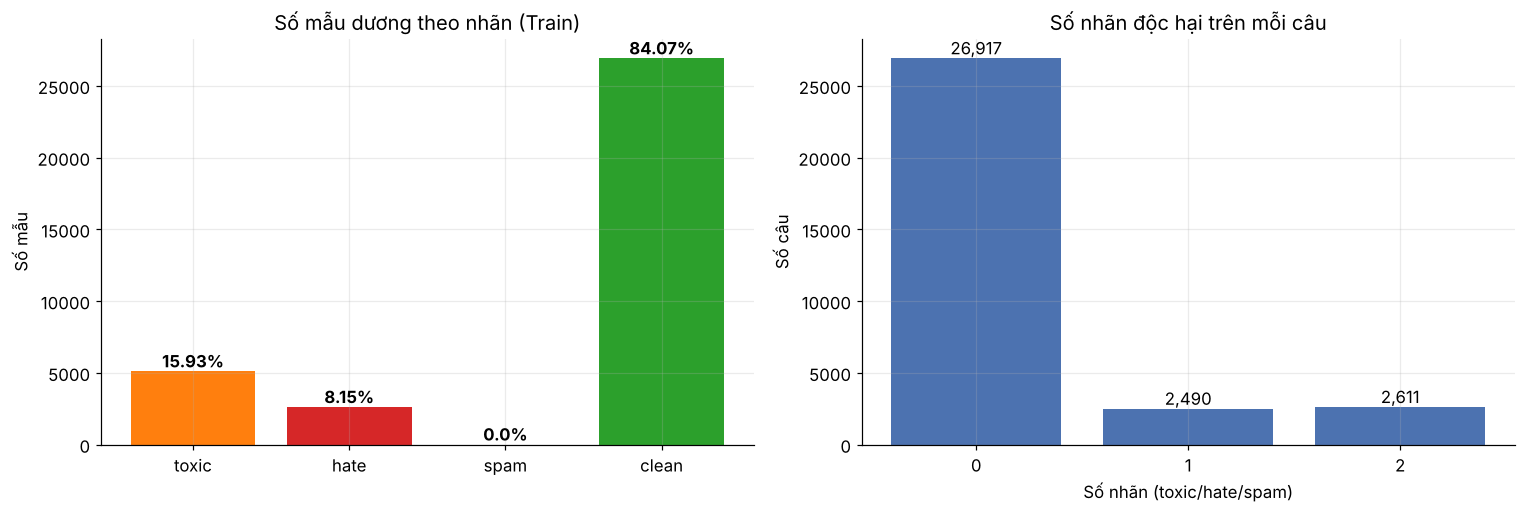

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

bars = axes[0].bar(label_stats.index, label_stats["Số mẫu dương"], color=[COLORS[l] for l in label_stats.index])
for b, p in zip(bars, label_stats["% mẫu dương"]):
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height(), f"{p}%", ha="center", va="bottom", fontweight="bold")
axes[0].set(title="Số mẫu dương theo nhãn (Train)", ylabel="Số mẫu")

# Số nhãn độc hại đồng thời trên mỗi câu
n_labels = tr[["toxic", "hate", "spam"]].sum(axis=1).value_counts().sort_index()
axes[1].bar(n_labels.index.astype(str), n_labels.values, color="#4C72B0")
for x, v in zip(n_labels.index.astype(str), n_labels.values):
    axes[1].text(x, v, f"{v:,}", ha="center", va="bottom")
axes[1].set(title="Số nhãn độc hại trên mỗi câu", xlabel="Số nhãn (toxic/hate/spam)", ylabel="Số câu")
plt.tight_layout(); plt.show()

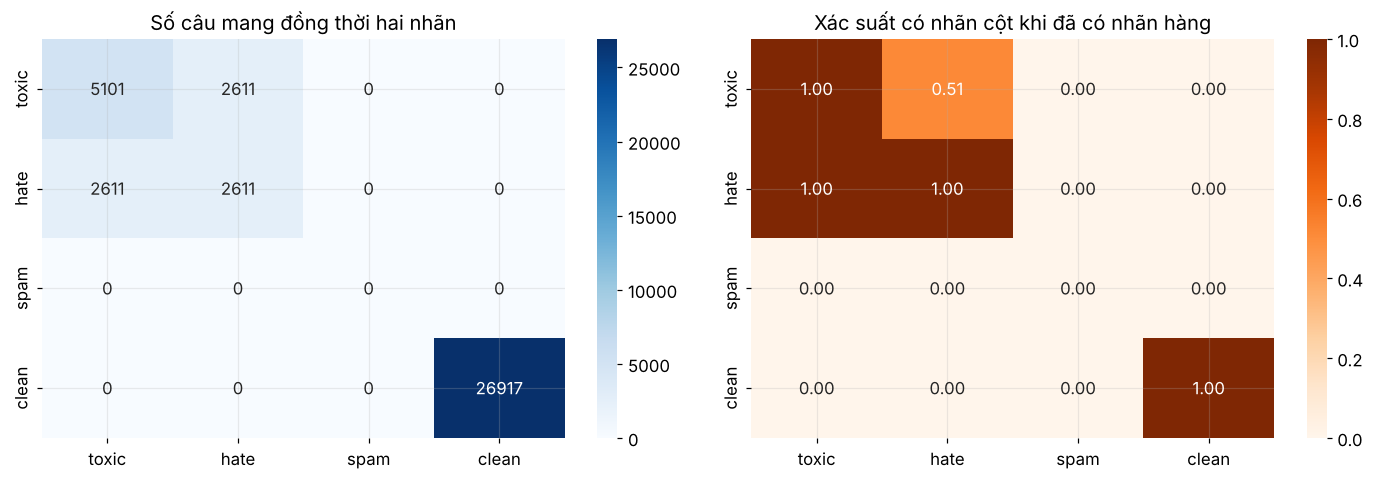

Số câu hate=1 nhưng toxic=0: 0  -> đúng quy ước hate ⇒ toxic ✓


In [ ]:
# Ma trận đồng xuất hiện + kiểm tra ràng buộc 'hate ⇒ toxic'
cooc = tr[LABELS].T.dot(tr[LABELS])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(cooc, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Số câu mang đồng thời hai nhãn")

cooc_pct = cooc.div(np.diag(cooc).clip(min=1), axis=0).round(3)   # P(cột | hàng)
sns.heatmap(cooc_pct, annot=True, fmt=".2f", cmap="Oranges", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("Xác suất có nhãn cột khi đã có nhãn hàng")
plt.tight_layout(); plt.show()

viol = int(((tr["hate"] == 1) & (tr["toxic"] == 0)).sum())
print(f"Số câu hate=1 nhưng toxic=0: {viol}  ->", "đúng quy ước hate ⇒ toxic ✓" if viol == 0 else "vi phạm quy ước ✗")

## 12. Mất cân bằng lớp & trọng số cho Focal Loss

Với mỗi nhãn nhị phân, mức mất cân bằng được đo bằng **tỉ lệ âm : dương** (`neg/pos`). Từ đó tính:
- **`pos_weight = neg / pos`** → tham số của `BCEWithLogitsLoss(pos_weight=...)`.
- **`alpha_focal = neg / N`** → hệ số cân bằng `α` của **Focal Loss** (kết hợp `γ = 2.0`), nhãn càng hiếm thì `α` càng lớn.

Nhãn **không có mẫu dương** không tính được (chia cho 0) → ghi `null` và xử lý riêng.

,pos,neg,tỉ lệ neg:pos,pos_weight,alpha_focal
nhãn,,,,,
toxic,5101,26917,5.28,5.2768,0.8407
hate,2611,29407,11.26,11.2627,0.9185
spam,0,32018,NaN,NaN,NaN
clean,26917,5101,0.19,0.1895,0.1593


Đã lưu configs/class_weights.json


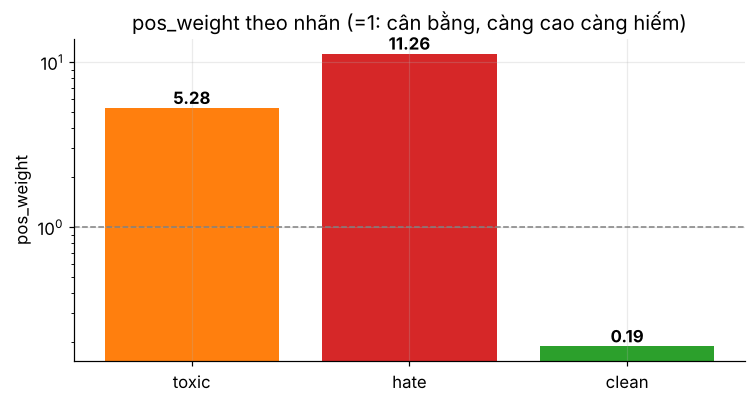

In [ ]:
rows = []
for c in LABELS:
    pos = int(tr[c].sum()); neg = N - pos
    rows.append({"nhãn": c, "pos": pos, "neg": neg,
                 "tỉ lệ neg:pos": round(neg / pos, 2) if pos else None,
                 "pos_weight": round(neg / pos, 4) if pos else None,
                 "alpha_focal": round(neg / N, 4) if pos else None})
weights_df = pd.DataFrame(rows).set_index("nhãn")
display(weights_df)

# Lưu file cho Tuần 2 (src/loss.py). NaN -> null để JSON hợp lệ.
cfg_dir = ROOT / "configs"; cfg_dir.mkdir(exist_ok=True)
wdict = weights_df[["pos_weight", "alpha_focal"]].astype(object)
wdict = wdict.where(wdict.notna(), None)
with open(cfg_dir / "class_weights.json", "w", encoding="utf-8") as f:
    json.dump(wdict.to_dict(orient="index"), f, ensure_ascii=False, indent=2)
print("Đã lưu configs/class_weights.json")

valid = weights_df.dropna(subset=["pos_weight"])
fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(valid.index, valid["pos_weight"], color=[COLORS[l] for l in valid.index])
ax.axhline(1, color="gray", ls="--", lw=1)
for b, v in zip(bars, valid["pos_weight"]):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}", ha="center", va="bottom", fontweight="bold")
ax.set(title="pos_weight theo nhãn (=1: cân bằng, càng cao càng hiếm)", ylabel="pos_weight")
if valid["pos_weight"].max() / max(valid["pos_weight"].min(), 1e-9) > 50:
    ax.set_yscale("log")
plt.tight_layout(); plt.show()

## 13. Từ khóa đặc trưng theo nhãn

Để kiểm tra nhanh tín hiệu của từng nhãn, tìm các từ **xuất hiện nhiều hơn hẳn** trong nhãn đó so với nhóm `clean` (điểm **log-odds** theo tần suất văn bản,
chỉ xét từ xuất hiện trong ít nhất 30 câu). Đây là cơ sở để đánh giá chất lượng tiền xử lý (teencode đã được chuẩn hóa chưa, có còn rác không).

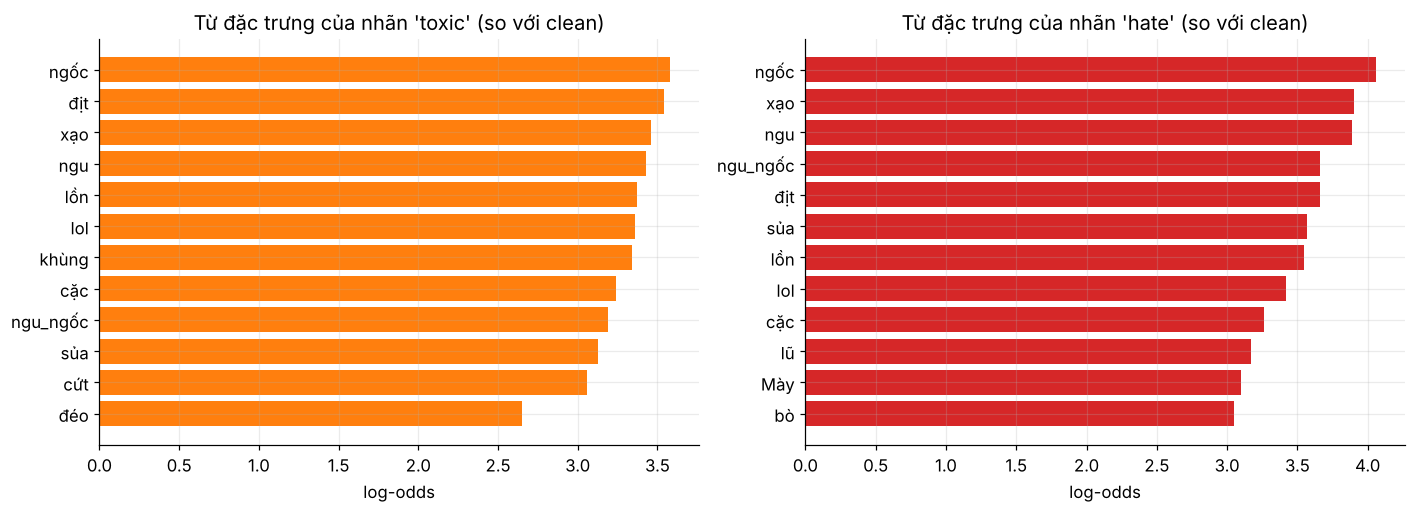

⚠️ **Phát hiện từ còn chữ HOA** (`Mày`): văn bản chưa được đưa về **chữ thường**, cùng một từ bị tách thành nhiều dạng (`Mày`/`mày`). Cần thêm bước `lower()` vào `preprocess_text` (phần Sinh viên 1).

In [ ]:
STOP = set("là và của có không được này thì mà cho với một những các em anh chị tôi mình rồi cũng như đã để khi nhưng ở "
           "trong đi ra lại nên vì nó bị còn ai gì thế vậy đó nào sẽ rất quá cả ạ nhé nha ơi".split())

def doc_freq(texts):
    df_ = Counter()
    for t in texts.astype(str):
        toks = {w for w in t.split() if re.fullmatch(r"[\w_]+", w) and not w.isdigit()
                and w not in STOP and len(w) > 1}
        df_.update(toks)
    return df_

clean_txt = tr.loc[tr["clean"] == 1, "text_processed"]
df_clean, n_clean = doc_freq(clean_txt), len(clean_txt)

def top_terms(label, k=12, min_df=30):
    sub = tr.loc[tr[label] == 1, "text_processed"]
    if len(sub) == 0:
        return pd.DataFrame(columns=["từ", "số câu", "log-odds"])
    dfl, n = doc_freq(sub), len(sub)
    out = []
    for w, c in dfl.items():
        if c < min_df: continue
        lo = np.log((c + 1) / (n - c + 1)) - np.log((df_clean.get(w, 0) + 1) / (n_clean - df_clean.get(w, 0) + 1))
        out.append((w, c, round(lo, 2)))
    return pd.DataFrame(sorted(out, key=lambda x: -x[2])[:k], columns=["từ", "số câu", "log-odds"])

shown = [l for l in ["toxic", "hate", "spam"] if tr[l].sum() >= 30]
fig, axes = plt.subplots(1, max(len(shown), 1), figsize=(6.5 * max(len(shown), 1), 4.8))
axes = np.atleast_1d(axes)
for ax, l in zip(axes, shown):
    t = top_terms(l)
    ax.barh(t["từ"][::-1], t["log-odds"][::-1], color=COLORS[l])
    ax.set(title=f"Từ đặc trưng của nhãn '{l}' (so với clean)", xlabel="log-odds")
plt.tight_layout(); plt.show()

# Kiểm tra chất lượng tiền xử lý: còn từ viết HOA nghĩa là chưa đưa về chữ thường
upper = sorted({w for l in shown for w in top_terms(l)["từ"] if w != w.lower()})
if upper:
    display(Markdown("⚠️ **Phát hiện từ còn chữ HOA** (" + ", ".join(f"`{w}`" for w in upper[:6]) +
                     "): văn bản chưa được đưa về **chữ thường**, cùng một từ bị tách thành nhiều dạng (`Mày`/`mày`). "
                     "Cần thêm bước `lower()` vào `preprocess_text` (phần Sinh viên 1)."))
else:
    display(Markdown("✓ Không còn từ viết HOA trong nhóm từ đặc trưng."))

## 14. Kết luận & khuyến nghị cho Tuần 2

In [ ]:
st = label_stats
pw = weights_df["pos_weight"]
def pct_of(l): return f"{st.loc[l, '% mẫu dương']}%"
hardest = pw.dropna().drop("clean", errors="ignore").idxmax() if pw.drop("clean", errors="ignore").notna().any() else "—"

display(Markdown(f'''
### Kết quả chính
- **Dữ liệu cuối:** {n_final:,} mẫu (Train {len(tr):,} · Val {len(va):,} · Test {len(te):,}) sau khi loại {removed:,} mẫu rỗng/trùng/mâu thuẫn nhãn ({removed / n_raw:.1%}).
- **Chia tập:** tỉ lệ nhãn lệch giữa các tập tối đa **{float(max_gap.max()):.2f} điểm phần trăm**; không có rò rỉ giữa các tập: **{"đạt" if leak_tv == leak_tt == leak_vt == 0 else "KHÔNG đạt"}**.
- **Phân bố nhãn (Train):** `clean` {pct_of("clean")} · `toxic` {pct_of("toxic")} · `hate` {pct_of("hate")} · `spam` {pct_of("spam")}.
- **Mất cân bằng:** nhãn khó nhất là **`{hardest}`** (`pos_weight` ≈ {float(pw[hardest]) if hardest in pw.index and pd.notna(pw.get(hardest)) else float("nan"):.2f}).
- **Emoji:** từ điển {len(GLOBAL_EMOJI_DICT)} mục, bao phủ {covered_occ / max(total_occ, 1):.1%} lượt emoji xuất hiện trong dữ liệu.

### Khuyến nghị cho Tuần 2
1. **Hàm mất mát:** dùng **Focal Loss** (`γ = 2.0`) với `alpha` lấy từ `configs/class_weights.json`; có thể so sánh với `BCEWithLogitsLoss(pos_weight=...)`.
2. **Độ đo:** dùng **Macro-F1** và **PR-AUC theo từng nhãn** (không dùng Accuracy vì lớp `clean` chiếm đa số).
3. **Ngưỡng quyết định:** chọn ngưỡng riêng cho từng nhãn trên tập Val (không cố định 0.5) vì nhãn hiếm cần ngưỡng thấp hơn.
4. **Chọn checkpoint** theo Macro-F1 trên Val, không theo loss.
5. **Nhãn `clean`** là phần bù của 3 nhãn còn lại; có thể giữ làm đầu ra thứ 4 hoặc suy ra từ 3 nhãn kia, cần thống nhất với SV1.
'''))


### Kết quả chính
- **Dữ liệu cuối:** 40,023 mẫu (Train 32,018 · Val 4,002 · Test 4,003) sau khi loại 3,375 mẫu rỗng/trùng/mâu thuẫn nhãn (7.8%).
- **Chia tập:** tỉ lệ nhãn lệch giữa các tập tối đa **0.02 điểm phần trăm**; không có rò rỉ giữa các tập: **đạt**.
- **Phân bố nhãn (Train):** `clean` 84.07% · `toxic` 15.93% · `hate` 8.15% · `spam` 0.0%.
- **Mất cân bằng:** nhãn khó nhất là **`hate`** (`pos_weight` ≈ 11.26).
- **Emoji:** từ điển 111 mục, bao phủ 92.4% lượt emoji xuất hiện trong dữ liệu.

### Khuyến nghị cho Tuần 2
1. **Hàm mất mát:** dùng **Focal Loss** (`γ = 2.0`) với `alpha` lấy từ `configs/class_weights.json`; có thể so sánh với `BCEWithLogitsLoss(pos_weight=...)`.
2. **Độ đo:** dùng **Macro-F1** và **PR-AUC theo từng nhãn** (không dùng Accuracy vì lớp `clean` chiếm đa số).
3. **Ngưỡng quyết định:** chọn ngưỡng riêng cho từng nhãn trên tập Val (không cố định 0.5) vì nhãn hiếm cần ngưỡng thấp hơn.
4. **Chọn checkpoint** theo Macro-F1 trên Val, không theo loss.
5. **Nhãn `clean`** là phần bù của 3 nhãn còn lại; có thể giữ làm đầu ra thứ 4 hoặc suy ra từ 3 nhãn kia, cần thống nhất với SV1.


## 15. Bàn giao & hạn chế

**Sản phẩm bàn giao của Sinh viên 2 (Tuần 1):**

| Sản phẩm | Vị trí |
|---|---|
| Từ điển Emoji | `data/dictionaries/emoji.json` |
| Script gộp 4 nhãn | `src/build_merged_dataset.py` → `data/raw/merged_dataset.csv` |
| Hàm tách từ `word_segmentation()` + `convert_emoji()` | `src/preprocessing.py` |
| Pipeline tiền xử lý + chia tập 80/10/10 | `src/split_data.py` → `data/processed/{train,val,test}.csv` |
| Trọng số lớp cho Tuần 2 | `configs/class_weights.json` |
| Backup dữ liệu sạch | Google Drive của nhóm |

**Hạn chế đã biết (cần thống nhất với nhóm/giảng viên):**
1. **Nhãn `spam`:** không bộ dữ liệu nào (ViHSD, ViCTSD) có sẵn nhãn này. Mặc định `spam = 0` nên chưa thể huấn luyện nhãn này; có luật heuristic
   (`--spam-rules`: link, số điện thoại, từ khóa quảng cáo) nhưng chỉ gán được rất ít mẫu và chưa kiểm chứng độ chính xác.
2. **Nhãn `hate` chỉ đến từ ViHSD**, còn `ViCTSD` chỉ có `toxic`; định nghĩa "toxic" giữa hai nguồn có thể không hoàn toàn đồng nhất.
3. **Nhiễu gán nhãn:** một phần câu trùng có nhãn mâu thuẫn (mục 8); các câu này đã bị loại, nhưng nhiễu tương tự có thể còn trong các câu không trùng.
4. **Tách từ** bằng `underthesea` có thể ghép sai quanh các cụm từ tục sau khi mở rộng teencode; nên so sánh với `pyvi`/VnCoreNLP trước khi chốt.